# **[실습] 뉴스 유사도**
* https://www.bigkinds.or.kr/

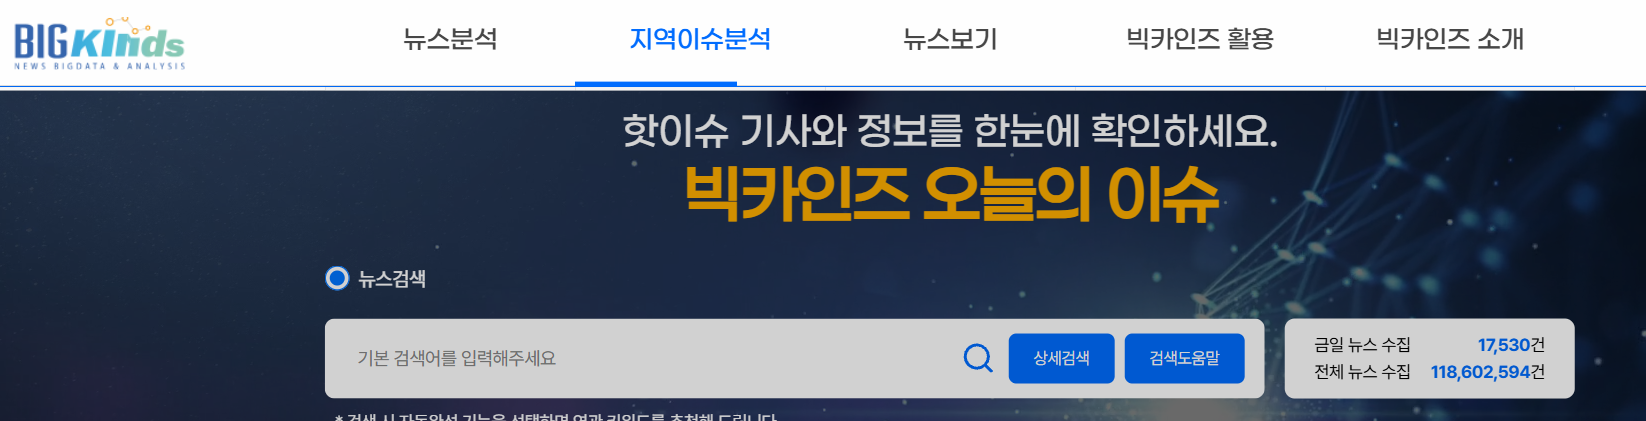

In [20]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.corpus import stopwords
from konlpy.tag import Okt

import warnings 
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("../datas/bigkinds_news.csv")
df.head(2)

,title,keyword,content
0,"송강 이준영, 피아노로 그린 구원 서사 ‘포핸즈’ 인기 이유","포핸즈,이준영,송강,기성세대,1위,윤석진,공희정,평론가,노력파,상승세,지상파,스릴러...",클래식 음악을 소재로 청춘의 우정과 성장을 다룬 tvN 토일드라마 ‘포핸즈’가 종영...
1,끝나지 않는 민주당 혁신당 갈등 조국 평택을 선거 도운 전 민주당원 징계에 혁신당 반발,"민주당,혁신당,평택,사무총장,페이스북,모양새,신장식,정춘생,당규,진영",더불어민주당이 지난 6월 치러진 경기 평택을 국회의원 재선거에서 민주당을 탈당하고 ...


# 결측 삭제

In [4]:
df = df.dropna()
df.shape

(12974, 3)

# 중복제거

In [5]:
df = df.drop_duplicates()
df.shape

(12960, 3)

In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 12960 entries, 0 to 12973
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    12960 non-null  str  
 1   keyword  12960 non-null  str  
 2   content  12960 non-null  str  
dtypes: str(3)
memory usage: 9.9 MB


# 데이터 정제(cleaning)

In [26]:
import re

def MY_TOKENIZER_FUNC(content):
    okt = Okt()
    word_list = okt.morphs(content, stem = True)
    p = re.compile(r'^[a-zA-Z0-9가-힣]{2,}$')
    res = [word for word in word_list if p.match(word)]
    return res

# 유사도 계산
* TF-IDF
* cosine_similarity

In [27]:
stop_words_list = stopwords.words('korea')

tfidf = TfidfVectorizer(stop_words=stop_words_list
                        , tokenizer=MY_TOKENIZER_FUNC  #--------데이터 정제 추가
                       )
                       
tfidf_matrix = tfidf.fit_transform(df['content'])      #-------- content vs. keyword
print(f"TFIDF 행렬 크기 : {tfidf_matrix.shape}")
print(f"사전크기(단어갯수) : {tfidf_matrix.shape[1]}")

#print(tfidf.vocabulary_)

TFIDF 행렬 크기 : (12960, 31858)
사전크기(단어갯수) : 31858


In [28]:
cosine_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)
cosine_matrix.shape

(12960, 12960)

In [29]:
cos_df = pd.DataFrame(cosine_matrix, index=[df['title'].str.lower()] , columns=[df['title'].str.lower()])
cos_df.head(2)

title,"송강 이준영, 피아노로 그린 구원 서사 ‘포핸즈’ 인기 이유",끝나지 않는 민주당 혁신당 갈등 조국 평택을 선거 도운 전 민주당원 징계에 혁신당 반발,"유엔사, 3개월 전 “북, 군사분계선 침범 증거 없어” 지금은 “정전협정 위반” 왜?",건강 평화 경제 잇는 ‘파주개성인삼축제’ 17일 개최,프랑스 극우 대선 후보의 새로운 악재 등장? 측근 ‘반유대주의 발언’ 의혹 논란,샌프란시스코 현대미술관서 bts rm 특별전 소장품 140점 전시,"조정훈 이준석 공동대표, 수도권 부동산정책 포럼 출범 친한계 빼고 보수 통합 시동","특검, ‘계엄 해제 표결 방해’ 추경호에게 징역 20년 구형 “헌법 배신하고 국민 기만”",“뚝 하면 죄송한 안내의 말씀” 제주공항 6편 중 1편 지연,"국힘 윤리위, ‘멱살’ 권영진 봐줬다 징계 수위 낮춰 차기 총선 공천 기회 부여",...,"鄭 노무현 조문 논란, 金 후단협 행보까지 당권 경쟁 ‘적통 논쟁’",남겨진 가족들도 무너지지 않도록 돌봄 필요,[365기도 on] <181> 따뜻한 마음으로 사람을 살리게 하소서,비판 여론에 밀린 ‘탈모 건보 적용’ 국민토론회 전격 취소,"[단독] 대통령 “직선제” 주문에도 축협, 정몽규 후임도 ‘체육관 선거’",선관위 특검 카드로 반전 노리는 與,[단독] 사퇴 분출 장동혁 다시 징계정치 내달 6일 윤리위 재가동,"“전 의원 비상대기” 민주, 단독 원구성 강행하나",미 이란 호르무즈 포성 ‘일단 멈춤’ 후속 실무 회담 두고선 다른 목소리,"李 “산업화 때 수도권 영남 올인 호남 홀대, 반도체 기회 요인됐다”"
title,,,,,,,,,,,,,,,,,,,,,
"송강 이준영, 피아노로 그린 구원 서사 ‘포핸즈’ 인기 이유",1.000000,0.014165,0.017007,0.008396,0.009176,0.009485,0.003518,0.005719,0.013186,0.016483,...,0.007379,0.001270,0.003445,0.005009,0.005336,0.003781,0.034961,0.013102,0.009271,0.002132
끝나지 않는 민주당 혁신당 갈등 조국 평택을 선거 도운 전 민주당원 징계에 혁신당 반발,0.014165,1.000000,0.017029,0.009768,0.033913,0.007987,0.077127,0.010493,0.002753,0.034840,...,0.063112,0.003613,0.009801,0.003223,0.015646,0.072151,0.032007,0.062881,0.022429,0.017862


# 유사기사  Top-N 조회

In [30]:
cos_df.loc['특검, ‘계엄 해제 표결 방해’ 추경호에게 징역 20년 구형  “헌법 배신하고 국민 기만”'].squeeze().sort_values(ascending=False)[1:5]

title                                   
특검, ‘계엄 해제표결 방해’ 추경호에 징역 20년 구형             0.790546
“윤석열과 내란의 편에 섰다”  박성재 항소심도 징역 25년 구형        0.506984
특검, ‘계엄 가담’ 김현태 전 707단장 징역 18년 구형 다음달 선고    0.496848
특검, ‘내란 가담’ 김현태에 징역 18년 구형                  0.463596
Name: (특검, ‘계엄 해제 표결 방해’ 추경호에게 징역 20년 구형  “헌법 배신하고 국민 기만”,), dtype: float64

<pre>
<b>content</b>                                
특검, ‘계엄 해제표결 방해’ 추경호에 징역 20년 구형             0.612103
특검, ‘내란 가담’ 김현태에 징역 18년 구형                  0.274658
“윤석열과 내란의 편에 섰다”  박성재 항소심도 징역 25년 구형        0.215700
특검, ‘계엄 가담’ 김현태 전 707단장 징역 18년 구형 다음달 선고    0.215476
Name: (특검, ‘계엄 해제 표결 방해’ 추경호에게 징역 20년 구형  “헌법 배신하고 국민 기만”,), dtype: float64

<b>keyword</b>                                                             
특검, ‘계엄 해제표결 방해’ 추경호에 징역 20년 구형                                           0.432613
“계엄 표결 방해 없었다”던 국힘의원들, 민주당에 화살 돌리나?  “빨리 모여 굉장히 의아했다”[법정 417호, 내란의 기록]    0.418450
계엄 때 “친위 쿠데타 내란 시도” 목소리 높인 안철수, 추경호 재판에선 “법적인 내란은 아니야”                    0.335083
추경호 ‘국회 계엄해제 방해’ 재판서 주진우 “계엄 직후, 위헌 위법 판단 불가능했다”                          0.276412
Name: (특검, ‘계엄 해제 표결 방해’ 추경호에게 징역 20년 구형  “헌법 배신하고 국민 기만”,), dtype: float64

<b>cleaning - content</b>                                
특검, ‘계엄 해제표결 방해’ 추경호에 징역 20년 구형             0.790546
“윤석열과 내란의 편에 섰다”  박성재 항소심도 징역 25년 구형        0.506984
특검, ‘계엄 가담’ 김현태 전 707단장 징역 18년 구형 다음달 선고    0.496848
특검, ‘내란 가담’ 김현태에 징역 18년 구형                  0.463596
Name: (특검, ‘계엄 해제 표결 방해’ 추경호에게 징역 20년 구형  “헌법 배신하고 국민 기만”,), dtype: float64

